# 05 — Final test-set evaluation
Final model: **EfficientNet-B0** (chosen on validation in notebook 04).
Educational prototype, not a clinical diagnostic system.

## 1. Setup: dataset (Kaggle) and checkpoint (upload)

In [2]:
KAGGLE_DATASET = "sainibharat10/neurovision-brain-mri"
import os, io, glob, shutil, zipfile
DATA, ART = "/content/data", "/content/artifacts"
os.makedirs(ART, exist_ok=True)
!pip -q install kagglehub
import kagglehub

def find_root(p):
    hits = glob.glob(f"{p}/**/train", recursive=True)
    return os.path.dirname(hits[0]) if hits else None

if not os.path.isdir(f"{DATA}/test"):
    try:
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception:
        kagglehub.login()
        path = kagglehub.dataset_download(KAGGLE_DATASET)
    root = find_root(path)
    if root is None:
        for z in glob.glob(f"{path}/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        for z in glob.glob("/content/_raw/**/*.zip", recursive=True):
            zipfile.ZipFile(z).extractall("/content/_raw")
        root = find_root("/content/_raw")
    assert root, "train/ folder not found"
    shutil.copytree(root, DATA, dirs_exist_ok=True)
print(sorted(os.listdir(DATA)))

CK = f"{ART}/effnet_b0_best.pth"
if not os.path.exists(CK):
    from google.colab import files
    for name, data in files.upload().items():        # upload neurovision_effnet_b0.zip (or effnet_b0_best.pth)
        if name.endswith(".zip"): zipfile.ZipFile(io.BytesIO(data)).extractall(ART)
        elif name.endswith(".pth"): open(CK, "wb").write(data)
assert os.path.exists(CK), "checkpoint not found"
print("checkpoint OK")

100%|██████████| 107M/107M [00:01<00:00, 103MB/s] 

Extracting files...


['test', 'train', 'val']


Saving neurovision_effnet_b0.zip to neurovision_effnet_b0.zip
checkpoint OK


In [3]:
import json, time, numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms as T, models
from sklearn.metrics import (classification_report, confusion_matrix, f1_score, balanced_accuracy_score,
                             precision_recall_fscore_support, ConfusionMatrixDisplay)

device = "cuda" if torch.cuda.is_available() else "cpu"; print("device:", device)
CLASSES = sorted(os.listdir(f"{DATA}/train"))
saved = json.load(open(f"{ART}/class_names.json")) if os.path.exists(f"{ART}/class_names.json") else CLASSES
assert saved == CLASSES, f"class order mismatch: {saved} vs {CLASSES}"

rows = [("test", c, f"{DATA}/test/{c}/{f}") for c in CLASSES for f in os.listdir(f"{DATA}/test/{c}")]
df = pd.DataFrame(rows, columns=["split", "cls", "path"])
IMG = 224
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
def load(p): return np.asarray(Image.open(p).convert("RGB").resize((IMG, IMG), Image.BILINEAR))
with ThreadPoolExecutor(8) as ex: X = torch.from_numpy(np.stack(list(ex.map(load, df.path)))).permute(0, 3, 1, 2).contiguous()
y = np.array([CLASSES.index(c) for c in df.cls])
norm = T.Normalize(MEAN, STD)
class TestDS(Dataset):                       # deterministic preprocessing: identical to validation in notebook 04
    def __len__(self): return len(y)
    def __getitem__(self, i): return norm(X[i].float() / 255), int(y[i])
dl = DataLoader(TestDS(), batch_size=32, shuffle=False, num_workers=2)
print("test images:", len(y), dict(zip(CLASSES, np.bincount(y))))

device: cuda
test images: 889 {'glioma': np.int64(328), 'meningioma': np.int64(221), 'no_tumor': np.int64(118), 'pituitary': np.int64(222)}


## 2. Load the final model

In [4]:
model = models.efficientnet_b0(weights=None)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(CLASSES))
ck = torch.load(CK, map_location=device)
assert ck["classes"] == CLASSES
model.load_state_dict(ck["model"]); model.to(device).eval()
print("checkpoint epoch:", ck["epoch"], "| val macro-F1 at save:", round(ck["val_macro_f1"], 4))

checkpoint epoch: 21 | val macro-F1 at save: 0.983


## 3. Evaluate on the test set (once)

TEST accuracy 0.9831 | macro-F1 0.9826 | balanced accuracy 0.9829 | errors 15 / 889

              precision    recall  f1-score   support

      glioma      0.982     0.985     0.983       328
  meningioma      0.982     0.968     0.975       221
    no_tumor      0.975     0.983     0.979       118
   pituitary      0.991     0.995     0.993       222

    accuracy                          0.983       889
   macro avg      0.982     0.983     0.983       889
weighted avg      0.983     0.983     0.983       889



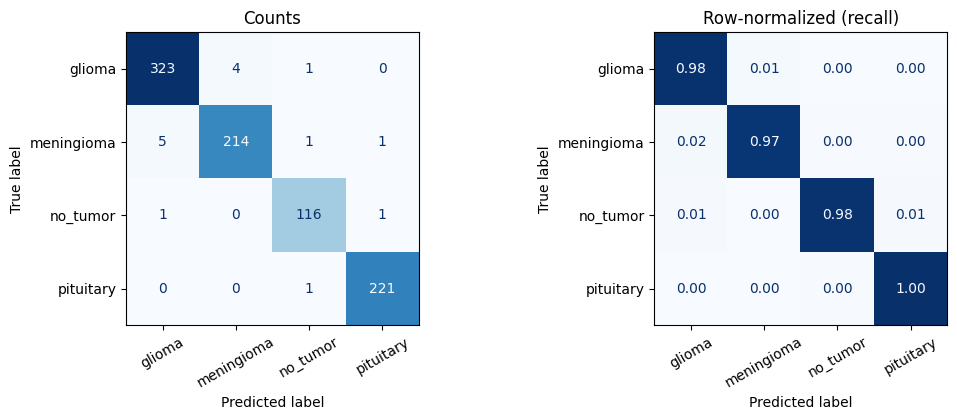

In [5]:
probs = []
with torch.no_grad():
    for xb, _ in dl:
        with torch.autocast(device_type="cuda", enabled=(device == "cuda")):
            probs.append(torch.softmax(model(xb.to(device)).float(), 1).cpu().numpy())
probs = np.concatenate(probs); pred = probs.argmax(1)

acc = float((pred == y).mean()); f1m = f1_score(y, pred, average="macro"); bacc = balanced_accuracy_score(y, pred)
print(f"TEST accuracy {acc:.4f} | macro-F1 {f1m:.4f} | balanced accuracy {bacc:.4f} | errors {(pred != y).sum()} / {len(y)}\n")
print(classification_report(y, pred, target_names=CLASSES, digits=3))
cm = confusion_matrix(y, pred)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax[0], cmap="Blues", xticks_rotation=30, colorbar=False)
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASSES).plot(
    ax=ax[1], cmap="Blues", xticks_rotation=30, colorbar=False, values_format=".2f")
ax[0].set_title("Counts"); ax[1].set_title("Row-normalized (recall)")
plt.tight_layout(); plt.savefig(f"{ART}/test_confusion_matrix.png", dpi=150); plt.show()

## 4. Error analysis

Tumor detection sensitivity: 0.9961  (3 tumors predicted as no_tumor of 771)
No-tumor specificity:        0.9831  (2 normal scans flagged of 118)

Mean confidence: correct 0.994 | wrong 0.768
Wrong predictions made with confidence > 0.9: 2


,path,true,pred,confidence
0,/content/data/test/glioma/glioma_test_00289.jpg,glioma,no_tumor,0.845
1,/content/data/test/glioma/glioma_test_00283.jpg,glioma,meningioma,0.848
2,/content/data/test/glioma/glioma_test_00196.jpg,glioma,meningioma,1.000
3,/content/data/test/glioma/glioma_test_00172.jpg,glioma,meningioma,0.993
4,/content/data/test/glioma/glioma_test_00222.jpg,glioma,meningioma,0.498
5,/content/data/test/meningioma/meningioma_test_...,meningioma,glioma,0.556
6,/content/data/test/meningioma/meningioma_test_...,meningioma,no_tumor,0.893
7,/content/data/test/meningioma/meningioma_test_...,meningioma,pituitary,0.770
8,/content/data/test/meningioma/meningioma_test_...,meningioma,glioma,0.825
9,/content/data/test/meningioma/meningioma_test_...,meningioma,glioma,0.735


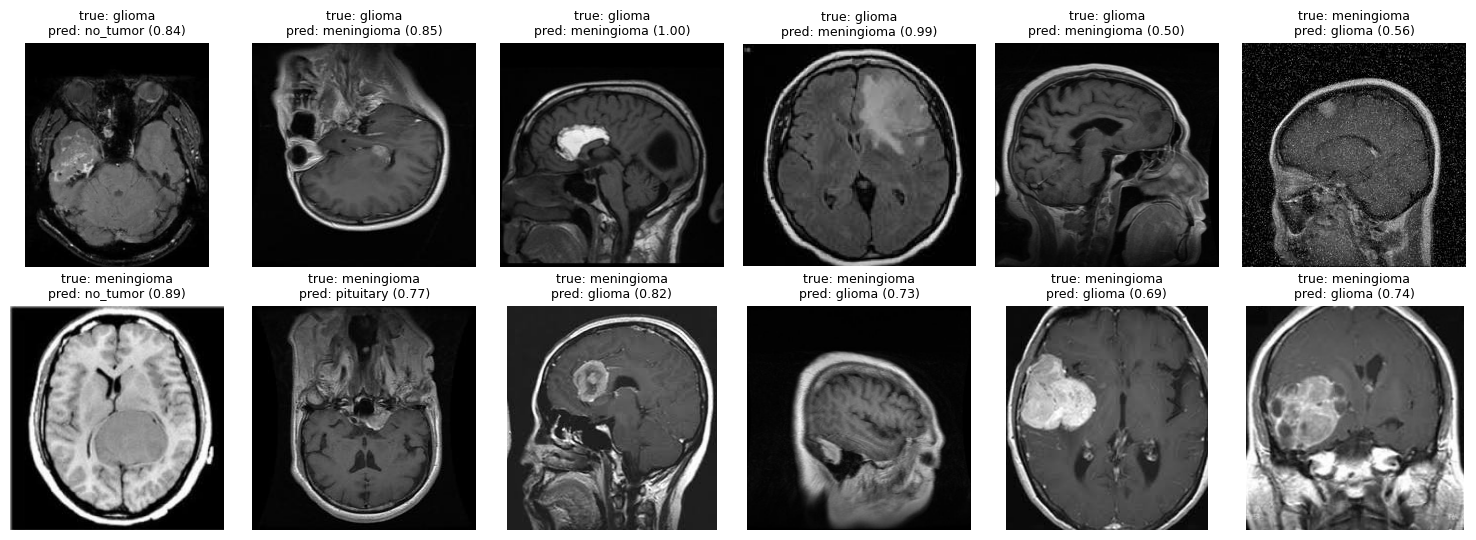

In [6]:
# Tumor vs no-tumor view: which mistakes matter most?
nt = CLASSES.index("no_tumor")
is_tumor, pred_tumor = y != nt, pred != nt
missed = int((is_tumor & ~pred_tumor).sum()); false_alarm = int((~is_tumor & pred_tumor).sum())
print(f"Tumor detection sensitivity: {1 - missed / is_tumor.sum():.4f}  ({missed} tumors predicted as no_tumor of {is_tumor.sum()})")
print(f"No-tumor specificity:        {1 - false_alarm / (~is_tumor).sum():.4f}  ({false_alarm} normal scans flagged of {(~is_tumor).sum()})")

conf = probs.max(1)
print(f"\nMean confidence: correct {conf[pred == y].mean():.3f} | wrong {conf[pred != y].mean():.3f}")
print("Wrong predictions made with confidence > 0.9:", int(((pred != y) & (conf > 0.9)).sum()))

wrong = np.where(pred != y)[0]
err = pd.DataFrame({"path": df.path.iloc[wrong].values, "true": [CLASSES[i] for i in y[wrong]],
                    "pred": [CLASSES[i] for i in pred[wrong]], "confidence": conf[wrong].round(3)})
err.to_csv(f"{ART}/test_errors.csv", index=False); display(err)

k = min(len(wrong), 12)
if k:
    fig, ax = plt.subplots(2, 6, figsize=(15, 5.5))
    for a in ax.ravel(): a.axis("off")
    for a, i in zip(ax.ravel(), wrong[:k]):
        a.imshow(Image.open(df.path.iloc[i]).convert("RGB"))
        a.set_title(f"true: {CLASSES[y[i]]}\npred: {CLASSES[pred[i]]} ({conf[i]:.2f})", fontsize=9)
    plt.tight_layout(); plt.savefig(f"{ART}/test_errors.png", dpi=130); plt.show()

## 5. Save final artifacts for the backend

In [7]:
p, r, f, s = precision_recall_fscore_support(y, pred, labels=range(len(CLASSES)), zero_division=0)
metrics = {
    "model": "EfficientNet-B0 (ImageNet-pretrained, fine-tuned)", "input_size": IMG, "normalization": {"mean": MEAN, "std": STD},
    "classes": CLASSES, "n_test": int(len(y)),
    "test": {"accuracy": acc, "macro_f1": f1m, "balanced_accuracy": bacc, "errors": int((pred != y).sum()),
             "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]), "f1": float(f[i]), "support": int(s[i])}
                           for i, c in enumerate(CLASSES)},
             "confusion_matrix": cm.tolist(),
             "tumor_sensitivity": 1 - missed / int(is_tumor.sum()), "no_tumor_specificity": 1 - false_alarm / int((~is_tumor).sum())},
    "validation": {"accuracy": 0.9843, "macro_f1": 0.9830, "note": "from notebook 04; best epoch selected on validation"},
    "comparison_validation": {"baseline_cnn": {"accuracy": 0.9204, "macro_f1": 0.9222},
                              "resnet18": {"accuracy": 0.9664, "macro_f1": 0.9657},
                              "efficientnet_b0": {"accuracy": 0.9843, "macro_f1": 0.9830}},
    "disclaimer": "Educational/research prototype, not a clinically validated diagnostic system.",
}
json.dump(metrics, open(f"{ART}/metrics.json", "w"), indent=2)
json.dump(CLASSES, open(f"{ART}/class_names.json", "w"))
torch.save({"model": model.state_dict(), "classes": CLASSES, "arch": "efficientnet_b0", "img_size": IMG,
            "mean": MEAN, "std": STD}, f"{ART}/best_model.pth")

from google.colab import files
keep = ["best_model.pth", "class_names.json", "metrics.json", "test_errors.csv", "test_confusion_matrix.png", "test_errors.png"]
with zipfile.ZipFile("/content/neurovision_final.zip", "w") as z:
    for n in keep:
        if os.path.exists(f"{ART}/{n}"): z.write(f"{ART}/{n}", n)
files.download("/content/neurovision_final.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>